# Unidad 4 — Modelos de Clasificación
## Ejercicio 2: Supervivencia en el Naufragio del Titanic — Naive Bayes

**Guía de Trabajos Prácticos — Algoritmos de clasificación sobre datasets públicos**

| Ítem | Detalle |
|---|---|
| **Problema** | Predecir si un pasajero **sobrevivió (1)** o **no sobrevivió (0)** al hundimiento del RMS Titanic. Clasificación binaria. |
| **Dataset** | *Titanic: Machine Learning from Disaster* (Kaggle, versión pública) — 891 pasajeros, 11 atributos + variable objetivo. |
| **Variable objetivo** | `Survived`: 0 = No · 1 = Sí. |
| **Algoritmo** | Naive Bayes (variantes **GaussianNB** y **CategoricalNB**). |
| **Entregables** | Este notebook (.ipynb) ejecutado de principio a fin + informe PDF. |

### Consigna general
1. Análisis exploratorio breve (tipos de datos, valores faltantes, distribución del target).
2. **Limpieza**: tabla de calidad por variable · faltantes (opciones + justificación) · duplicados · consistencia (espacios, mayúsculas/minúsculas, categorías raras) · atípicos (decisión + justificación, y cómo influyen según la variante de Naive Bayes) · **tabla de decisiones** (problema, evidencia, acción, justificación).
3. **Preprocesamiento**: discretización, codificación de categóricas, escalado si corresponde (justificado), división train/test 70/30.
4. Entrenar Naive Bayes.
5. Matriz de confusión y métricas de calidad.
6. Conclusión breve: por qué Naive Bayes es buena opción, sus límites, ventajas y mejoras posibles.


In [1]:
# Configuración general del notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, KBinsDiscretizer
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             RocCurveDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)

print("Entorno listo: pandas", pd.__version__, "| scikit-learn instalado | semilla", RANDOM_STATE)


Entorno listo: pandas 2.3.3 | scikit-learn instalado | semilla 42


## 1. Carga de datos

Se lee `data/titanic.csv` si existe; si no, se descarga desde el repositorio público de Kaggle en GitHub.


In [2]:
from pathlib import Path
import urllib.request

LOCAL = Path("data/titanic.csv")
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

if not LOCAL.exists():
    LOCAL.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, LOCAL)
    print(f"Dataset descargado en {LOCAL}")

df = pd.read_csv(LOCAL)
print("Shape:", df.shape)
df.head()


Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Análisis exploratorio breve

Tipos de datos, valores faltantes y distribución de `Survived`.


In [3]:
print("=== Tipos de datos ===")
print(df.dtypes.value_counts(), "\n")
print("Numéricas:", list(df.select_dtypes(include="number").columns))
print("Categóricas/texto:", list(df.select_dtypes(include="object").columns), "\n")

print("=== Valores faltantes ===")
nulos = df.isna().sum()
tabla_nulos = pd.DataFrame({"nulos": nulos[nulos > 0],
                            "%_nulos": (nulos[nulos > 0] / len(df) * 100).round(2)})
print(tabla_nulos if len(tabla_nulos) else "Sin valores faltantes")

print("\n=== Distribución del target ===")
print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True).round(3))


=== Tipos de datos ===
int64      5
object     5
float64    2
Name: count, dtype: int64 

Numéricas: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categóricas/texto: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'] 

=== Valores faltantes ===
          nulos  %_nulos
Age         177    19.87
Cabin       687    77.10
Embarked      2     0.22

=== Distribución del target ===
Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


### Distribución del target y faltantes por columna

Barras de `Survived` (38.4 % vs 61.6 %) y de la cantidad de nulos por variable (Age 19.9 %, Cabin 77.1 %, Embarked 0.2 %).

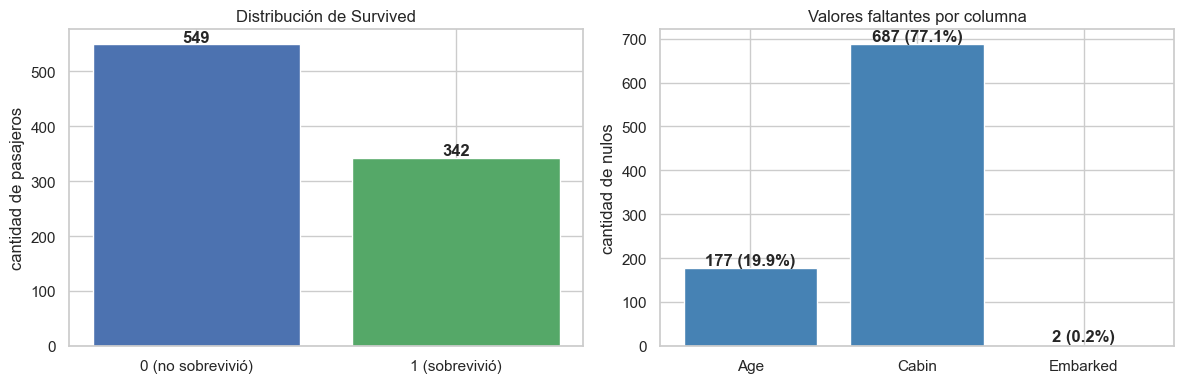

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df["Survived"].value_counts().reindex([0, 1])
axes[0].bar(["0 (no sobrevivió)", "1 (sobrevivió)"], counts.values,
            color=["#4c72b0", "#55a868"])
axes[0].set_title("Distribución de Survived")
axes[0].set_ylabel("cantidad de pasajeros")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontweight="bold")

nulos_plot = df[["Age", "Cabin", "Embarked"]].isna().sum()
axes[1].bar(nulos_plot.index, nulos_plot.values, color="steelblue")
axes[1].set_title("Valores faltantes por columna")
axes[1].set_ylabel("cantidad de nulos")
for i, v in enumerate(nulos_plot.values):
    axes[1].text(i, v + 8, f"{v} ({v/len(df)*100:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


## 3. Tabla de calidad por variable

Cantidad y porcentaje de nulos, cantidad de valores únicos y tipo de dato de cada columna.


In [5]:
calidad = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
    "%_unicos": (df.nunique() / len(df) * 100).round(2),
    "n_filas": len(df),
})
calidad


,tipo_dato,nulos,%_nulos,valores_unicos,%_unicos,n_filas
PassengerId,int64,0,0.00,891,100.00,891
Survived,int64,0,0.00,2,0.22,891
Pclass,int64,0,0.00,3,0.34,891
Name,object,0,0.00,891,100.00,891
Sex,object,0,0.00,2,0.22,891
Age,float64,177,19.87,88,9.88,891
SibSp,int64,0,0.00,7,0.79,891
Parch,int64,0,0.00,7,0.79,891
Ticket,object,0,0.00,681,76.43,891
Fare,float64,0,0.00,248,27.83,891


## 4. Valores faltantes: opciones y decisión

**Situación detectada:** `Age` 177 nulos (19.9 %), `Cabin` 687 nulos (77.1 %), `Embarked` 2 nulos (0.2 %).

| Variable | Opciones evaluadas | Decisión | Justificación |
|---|---|---|---|
| **Age** (19.9 %) | (a) eliminar 177 filas · (b) imputar media global · (c) **imputar mediana por grupo Pclass × Sex** · (d) KNNImputer | **(c)** | Eliminar perdería el 20 % de la muestra; la media global ignora que los niños viajaban en 3ª clase y las mujeres en 1ª; la mediana por grupo conserva ese patrón. KNN es más complejo sin ganancia justificada. |
| **Embarked** (0.2 %) | (a) eliminar 2 filas · (b) **imputar moda ('S')** | **(b)** | 2 registros (0.2 %): eliminarlos aporta nada y la moda ('Southampton', 644 casos) es la más probable. |
| **Cabin** (77.1 %) | (a) imputar · (b) eliminar columna · (c) **crear indicador HasCabin y eliminar Cabin** | **(c)** | Con 77 % de nulos no se puede imputar creíblemente; el hecho de *tener cabina registrada* sí es informativo (pasajeros de 1ª clase) y se conserva como flag binario. |


In [6]:
# (b) Embarked: moda
moda_embarked = df["Embarked"].mode()[0]
df["Embarked"] = df["Embarked"].fillna(moda_embarked)

# (c) Age: mediana por grupo Pclass x Sex
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda s: s.fillna(s.median()))

# (c) Cabin: indicador HasCabin + eliminación de la columna
df["HasCabin"] = df["Cabin"].notna().astype(int)
df = df.drop(columns=["Cabin"])

print("Nulos restantes por columna:")
print(df.isna().sum()[lambda s: s > 0] if df.isna().sum().sum() > 0 else "Sin valores faltantes -> 0 nulos")
print("Registros con cabina conocida (HasCabin=1):", int(df["HasCabin"].sum()))


Nulos restantes por columna:
Sin valores faltantes -> 0 nulos
Registros con cabina conocida (HasCabin=1): 204


### Verificación de la imputación de `Age`

Comparación de las distribuciones imputadas por grupo (p. ej. 1ª vs 3ª clase).

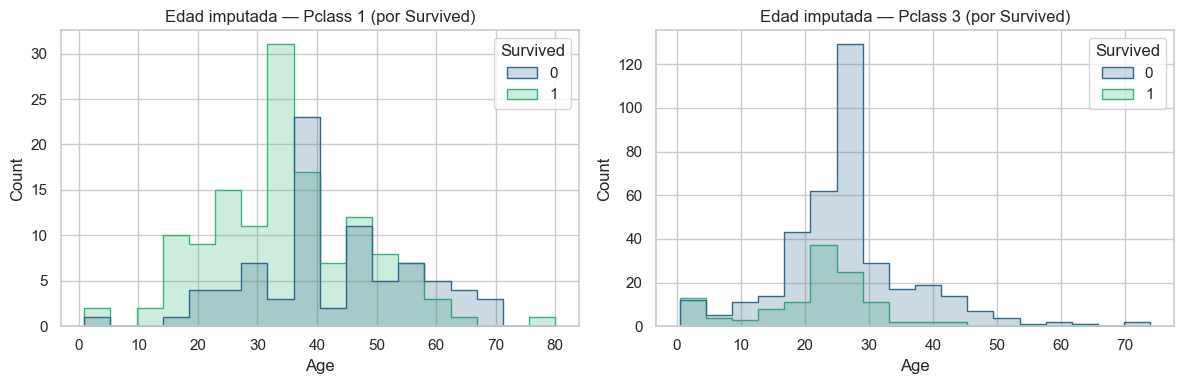

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pclass in zip(axes, [1, 3]):
    datos = df[df["Pclass"] == pclass]
    sns.histplot(data=datos, x="Age", hue="Survived", bins=18, ax=ax, kde=False,
                 palette="viridis", element="step")
    ax.set_title(f"Edad imputada — Pclass {pclass} (por Survived)")
plt.tight_layout()
plt.show()


## 5. Duplicados

Contamos registros repetidos y decidimos su tratamiento.


In [8]:
duplicados = int(df.duplicated().sum())
print("Registros duplicados exactos:", duplicados, f"({duplicados/len(df)*100:.2f}%)")

if duplicados > 0:
    print("Decisión: eliminar duplicados (mantener el primer registro).")
    df = df.drop_duplicates().reset_index(drop=True)
else:
    print("Decisión: no hay duplicados -> se conservan los 891 registros originales.")
print("Shape final tras duplicados:", df.shape)


Registros duplicados exactos: 0 (0.00%)
Decisión: no hay duplicados -> se conservan los 891 registros originales.
Shape final tras duplicados: (891, 12)


## 6. Consistencia: espacios, mayúsculas, categorías y feature engineering

1. **Espacios / caja**: `str.strip()` y verificación de cambios en el número de categorías.
2. **Título extraído del nombre**: `Name` contiene el tratamiento ("Mr.", "Miss.", "Dr.") → se extrae la columna `Title` y se unifican títulos raros (< 10 ocurrencias) en `Rare`, además de sinónimos (`Mlle`/`Ms` → `Miss`, `Mme` → `Mrs`, `Don` → `Mr`).
3. **Columnas sin valor predictivo**: `PassengerId` (identificador único), `Ticket` (681 valores únicos ≈ uno por fila → ruido) y `Name` (ya extraído como `Title`) se eliminan.
4. **`SibSp` + `Parch`** se reemplazan por `FamilySize = SibSp + Parch + 1` para no contar la misma evidencia dos veces (Naive Bayes asume independencia condicional).


In [9]:
ANTES = {c: df[c].nunique() for c in ["Sex", "Embarked", "Pclass"]}
for c in ["Sex", "Embarked"]:
    df[c] = df[c].astype(str).str.strip().str.lower()
DESPUES = {c: df[c].nunique() for c in ["Sex", "Embarked", "Pclass"]}
print("Categorías antes/después de strip()+lower:", {c: (ANTES[c], DESPUES[c]) for c in ANTES})
print("Valores de Embarked:", sorted(df["Embarked"].unique()))
print("Valores de Sex:", sorted(df["Sex"].unique()))


Categorías antes/después de strip()+lower: {'Sex': (2, 2), 'Embarked': (3, 3), 'Pclass': (3, 3)}
Valores de Embarked: ['c', 'q', 's']
Valores de Sex: ['female', 'male']


### *Feature engineering*: `Title`, `FamilySize` y descartes

Se extrae el título del nombre (unificando sinónimos y los raros), se crea `FamilySize` y se descartan columnas sin valor predictivo.

In [10]:
df["Title"] = df["Name"].str.extract(r",\s*([A-Za-z]+)\s*\.", expand=False)
print("Títulos originales (sin imputar):")
print(df["Title"].value_counts(dropna=False), "\n")

# Nombre no estándar ("Rothes, the Countess. of ...") -> se agrupa como Rare
df["Title"] = df["Title"].fillna("Rare")

df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Don": "Mr"})
raros = df["Title"].value_counts()
raros = raros[raros < 10].index.tolist()
df["Title"] = df["Title"].replace(raros, "Rare")
print("Títulos unificados (raros ->", raros, "):")
print(df["Title"].value_counts(dropna=False))

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df = df.drop(columns=["PassengerId", "Name", "Ticket", "SibSp", "Parch"])
print("\nShape tras consistencia/ingeniería:", df.shape)
print("Columnas:", list(df.columns))


Títulos originales (sin imputar):
Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Mlle          2
Major         2
Col           2
NaN           1
Capt          1
Ms            1
Sir           1
Lady          1
Mme           1
Don           1
Jonkheer      1
Name: count, dtype: int64 

Títulos unificados (raros -> ['Dr', 'Rev', 'Major', 'Col', 'Lady', 'Sir', 'Capt', 'Rare', 'Jonkheer'] ):
Title
Mr        518
Miss      185
Mrs       126
Master     40
Rare       22
Name: count, dtype: int64

Shape tras consistencia/ingeniería: (891, 9)
Columnas: ['Survived', 'Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'HasCabin', 'Title', 'FamilySize']


## 7. Valores atípicos: análisis, decisión e influencia en Naive Bayes

Método del rango intercuartílico (RIC/IQR) y asimetría (skewness) sobre las numéricas.

**Cómo influyen según la variante de Naive Bayes:**

- **GaussianNB** estima media y desvío por atributo: `Fare` tiene cola larga extrema (máx 512 vs mediana 14.45, asimetría 4.79) que desplaza fuertemente media/std → se aplica `log1p`. `Age` tras la imputación por grupos queda con asimetría 0.534 y 3.7 % de atípicos IQR → se conserva.
- **CategoricalNB** solo ve categorías: tras discretizar por cuantiles, los valores atípicos caen en el bin extremo y su influencia queda acotada.
- Naive Bayes **no exige eliminar atípicos** (no calcula distancias ni minimiza SSE como K-means/KNN): decidimos **transformar o conservar**, nunca eliminar registros.


In [11]:
numericas = ["Age", "Fare", "FamilySize"]

q1 = df[numericas].quantile(0.25)
q3 = df[numericas].quantile(0.75)
iqr = q3 - q1
out_at = ((df[numericas] < q1 - 1.5 * iqr) | (df[numericas] > q3 + 1.5 * iqr)).sum()

tabla_out = pd.DataFrame({
    "min": df[numericas].min(), "Q1": q1, "mediana": df[numericas].median(),
    "Q3": q3, "max": df[numericas].max(),
    "n_outliers_IQR": out_at,
    "%_outliers": (out_at / len(df) * 100).round(2),
    "asimetria": df[numericas].skew().round(3),
}).sort_values("%_outliers", ascending=False)
tabla_out


,min,Q1,mediana,Q3,max,n_outliers_IQR,%_outliers,asimetria
Fare,0.00,7.9104,14.4542,31.0,512.3292,116,13.02,4.787
FamilySize,1.00,1.0000,1.0000,2.0,11.0000,91,10.21,2.727
Age,0.42,21.5000,26.0000,36.0,80.0000,33,3.70,0.534


### Boxplots de las numéricas

Gráficos de cajas de `Age`, `Fare` y `FamilySize` para visualizar los atípicos detectados con el método IQR.

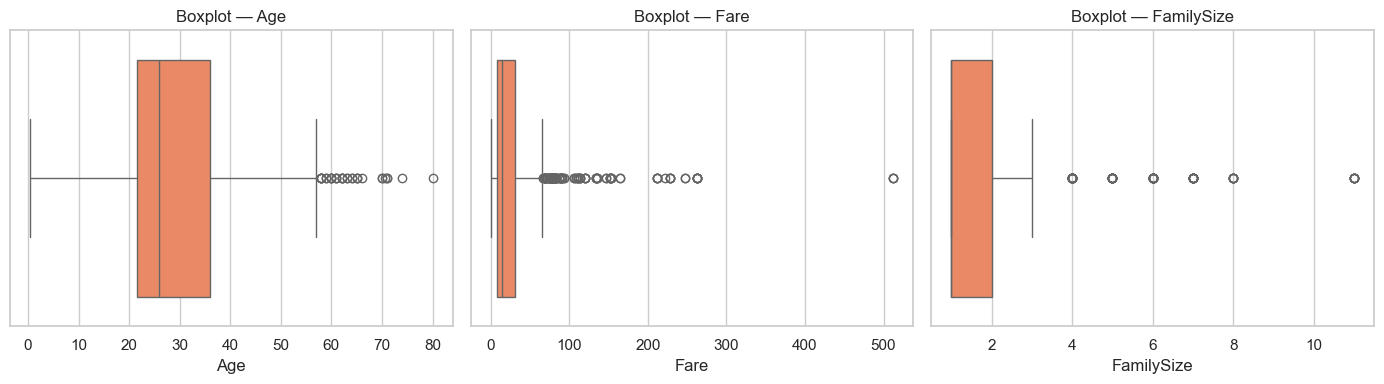

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Age", "Fare", "FamilySize"]):
    sns.boxplot(x=df[col], ax=ax, color="coral")
    ax.set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.show()


### Decisión sobre atípicos: `log1p` en `Fare`

Se transforma `Fare` (asimetría 4.79) y se justifica por qué se conservan `Age` y `FamilySize`.

In [13]:
def n_outliers(s):
    a, b = s.quantile(0.25), s.quantile(0.75)
    r = b - a
    return int(((s < a - 1.5 * r) | (s > b + 1.5 * r)).sum())

print("Fare      -> skew", round(df["Fare"].skew(), 3), "| outliers IQR:", n_outliers(df["Fare"]))
df["Fare_log"] = np.log1p(df["Fare"])
print("Fare_log  -> skew", round(df["Fare_log"].skew(), 3), "| outliers IQR:", n_outliers(df["Fare_log"]))
print("Age       -> skew", round(df["Age"].skew(), 3), "| outliers IQR:", n_outliers(df["Age"]),
      "-> se conserva sin transformar")

df = df.drop(columns=["Fare"])


Fare      -> skew 4.787 | outliers IQR: 116
Fare_log  -> skew 0.395 | outliers IQR: 31
Age       -> skew 0.534 | outliers IQR: 33 -> se conserva sin transformar


## 8. Tabla de decisiones de limpieza


In [14]:
decisiones = pd.DataFrame([
    {
        "problema detectado": "Age con valores faltantes",
        "evidencia": "177 nulos = 19.9 % de los registros",
        "accion tomada": "Imputación con la mediana agrupada por Pclass x Sex",
        "justificacion": "Eliminar (20 % de la muestra) descarta información; la mediana global ignora la estructura de edad por clase y sexo; la mediana por grupo la conserva",
    },
    {
        "problema detectado": "Embarked con valores faltantes",
        "evidencia": "2 nulos = 0.2 %",
        "accion tomada": "Imputación con la moda ('S' = Southampton, 644 pasajeros)",
        "justificacion": "Con solo 2 casos, la categoría más frecuente es la más probable y no altera la distribución",
    },
    {
        "problema detectado": "Cabin con valores faltantes masivos",
        "evidencia": "687 nulos = 77.1 %",
        "accion tomada": "Se elimina Cabin y se crea la variable binaria HasCabin (0/1)",
        "justificacion": "77 % de nulos imposibilita una imputación creíble; el indicador de 'cabina registrada' conserva la señal (correlaciona con 1ª clase) sin inventar datos",
    },
    {
        "problema detectado": "Registros duplicados",
        "evidencia": "duplicated() = 0 sobre 891 filas (0 %)",
        "accion tomada": "Se conservan los 891 registros",
        "justificacion": "Sin duplicados no hay doble conteo en las frecuencias P(xi|y)",
    },
    {
        "problema detectado": "Espacios / mayúsculas en Sex y Embarked",
        "evidencia": "strip()+lower() no cambian el número de categorías (2 y 3)",
        "accion tomada": "Se aplica limpieza defensiva y se pasa a minúsculas",
        "justificacion": "Evita duplicar categorías si el CSV trajera 'male '/'Male'",
    },
    {
        "problema detectado": "Títulos poco frecuentes en Name",
        "evidencia": "Dr=7, Rev=6, Col=2, Major=2, Capt=1, Jonkheer=1, Lady=1, Sir=1 (< 10 c/u); 1 nombre no estándar ('Rothes, the Countess. of ...') sin título parseable",
        "accion tomada": "Extraer Title del Name; NaN -> 'Rare'; sinónimos unificados (Mlle/Ms->Miss, Mme->Mrs, Don->Mr) y títulos < 10 agrupados en 'Rare' (22 casos)",
        "justificacion": "Las categorías casi vacías estiman mal P(Title|y); el título resume género/estado civil sin el ruido del texto libre",
    },
    {
        "problema detectado": "Columnas sin valor predictivo",
        "evidencia": "PassengerId único por fila; Ticket con 681 valores únicos (76 %); Name redundante con Title",
        "accion tomada": "Se eliminan PassengerId, Ticket y Name",
        "justificacion": "Aportan ruido/aleatoriedad: Naive Bayes multiplicaría verosimilitudes de categorías casi únicas que no generalizan",
    },
    {
        "problema detectado": "Atípicos en Fare",
        "evidencia": "116 outliers IQR (13.0 %), asimetría 4.79, máx 512.33 vs mediana 14.45",
        "accion tomada": "Transformación log1p (se conservan los registros)",
        "justificacion": "GaussianNB estima media/std: la cola extrema de Fare los distorsiona; log1p comprime la escala. En CategoricalNB la discretización por cuantiles acota los atípicos al bin superior",
    },
    {
        "problema detectado": "Atípicos en Age",
        "evidencia": "33 outliers IQR (3.7 %), asimetría 0.534 (tras imputar por grupos)",
        "accion tomada": "Se conservan sin transformar",
        "justificacion": "Rango plausible (0.42 a 80 años) y asimetría moderada (< 1); Naive Bayes no exige eliminar atípicos y al discretizar por cuantiles su efecto queda acotado",
    },
    {
        "problema detectado": "Redundancia SibSp + Parch",
        "evidencia": "Ambas cuentan integrantes del grupo familiar del pasajero",
        "accion tomada": "Se reemplazan por FamilySize = SibSp + Parch + 1",
        "justificacion": "Naive Bayes asume independencia condicional; evitar duplicar la misma evidencia reduce la sobreestimación de probabilidad",
    },
    {
        "problema detectado": "Desbalance de clases",
        "evidencia": "549 no sobrevivieron (61.6 %) vs 342 sobrevivientes (38.4 %)",
        "accion tomada": "Split estratificado 70/30 y métricas Precision/Recall/F1 además de accuracy",
        "justificacion": "La estratificación mantiene la proporción real en train y test; accuracy solo engañaría con clase mayoritaria",
    },
])
decisiones


,problema detectado,evidencia,accion tomada,justificacion
0,Age con valores faltantes,177 nulos = 19.9 % de los registros,Imputación con la mediana agrupada por Pclass x Sex,Eliminar (20 % de la muestra) descarta información; la mediana global ignora la estructura de edad por clase y sexo; la mediana por grupo la conserva
1,Embarked con valores faltantes,2 nulos = 0.2 %,"Imputación con la moda ('S' = Southampton, 644 pasajeros)","Con solo 2 casos, la categoría más frecuente es la más probable y no altera la distribución"
2,Cabin con valores faltantes masivos,687 nulos = 77.1 %,Se elimina Cabin y se crea la variable binaria HasCabin (0/1),77 % de nulos imposibilita una imputación creíble; el indicador de 'cabina registrada' conserva la señal (correlaciona con 1ª clase) sin inventar datos
3,Registros duplicados,duplicated() = 0 sobre 891 filas (0 %),Se conservan los 891 registros,Sin duplicados no hay doble conteo en las frecuencias P(xi|y)
4,Espacios / mayúsculas en Sex y Embarked,strip()+lower() no cambian el número de categorías (2 y 3),Se aplica limpieza defensiva y se pasa a minúsculas,Evita duplicar categorías si el CSV trajera 'male '/'Male'
5,Títulos poco frecuentes en Name,"Dr=7, Rev=6, Col=2, Major=2, Capt=1, Jonkheer=1, Lady=1, Sir=1 (< 10 c/u); 1 nombre no estándar ('Rothes, the Countess. of ...') sin título parseable","Extraer Title del Name; NaN -> 'Rare'; sinónimos unificados (Mlle/Ms->Miss, Mme->Mrs, Don->Mr) y títulos < 10 agrupados en 'Rare' (22 casos)",Las categorías casi vacías estiman mal P(Title|y); el título resume género/estado civil sin el ruido del texto libre
6,Columnas sin valor predictivo,PassengerId único por fila; Ticket con 681 valores únicos (76 %); Name redundante con Title,"Se eliminan PassengerId, Ticket y Name",Aportan ruido/aleatoriedad: Naive Bayes multiplicaría verosimilitudes de categorías casi únicas que no generalizan
7,Atípicos en Fare,"116 outliers IQR (13.0 %), asimetría 4.79, máx 512.33 vs mediana 14.45",Transformación log1p (se conservan los registros),GaussianNB estima media/std: la cola extrema de Fare los distorsiona; log1p comprime la escala. En CategoricalNB la discretización por cuantiles acota los atípicos al bin superior
8,Atípicos en Age,"33 outliers IQR (3.7 %), asimetría 0.534 (tras imputar por grupos)",Se conservan sin transformar,Rango plausible (0.42 a 80 años) y asimetría moderada (< 1); Naive Bayes no exige eliminar atípicos y al discretizar por cuantiles su efecto queda acotado
9,Redundancia SibSp + Parch,Ambas cuentan integrantes del grupo familiar del pasajero,Se reemplazan por FamilySize = SibSp + Parch + 1,Naive Bayes asume independencia condicional; evitar duplicar la misma evidencia reduce la sobreestimación de probabilidad


## 9. Preprocesamiento

- **Codificación de categóricas**:
  - **GaussianNB**: `OneHotEncoder` para `Sex`, `Embarked` y `Title` (nominales, sin orden); `Pclass` se mantiene como entero ordenado (1 < 2 < 3 es una relación real).
  - **CategoricalNB**: `OrdinalEncoder` (índices `0..k-1`), el formato exacto que exige el algoritmo.
- **Discretización**: `KBinsDiscretizer(strategy="quantile", n_bins=5)` sobre `Age` y `Fare_log` para CategoricalNB (convierte numéricas en categorías y acota atípicos a los bins extremos). `FamilySize` **no se discretiza**: es ya una categoría discreta natural (1 a 11) y sus cuantiles son degenerados (mediana = Q1 = 1), lo que produciría bins de ancho nulo.
- **Escalado**: **no se aplica, justificado**: Naive Bayes estima $P(x_i \mid y)$ por variable de forma independiente; en GaussianNB, estandarizar cambia media y desvío en la misma proporción sin mover la frontera de decisión, y en CategoricalNB los valores se usan como índices de categoría (escalar no tiene significado). No depende de la escala a diferencia de KNN/SVM.
- **División train/test**: 70 % / 30 % estratificada por `Survived`, `random_state = 42`.


In [15]:
CAT_COLS = ["Sex", "Embarked", "Title"]          # nominales
ORD_COL = ["Pclass"]                              # ordinal natural 1<2<3
NUM_COLS = ["Age", "Fare_log", "FamilySize"]      # continuas
BIN_COLS = ["Age", "Fare_log"]                    # se discretizan para CategoricalNB
FAMILY_COL = ["FamilySize"]                       # categoría discreta natural (1-11), sin discretizar

X = df[CAT_COLS + ORD_COL + NUM_COLS].copy()
y = df["Survived"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción target train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Proporción target test :", y_test.value_counts(normalize=True).round(3).to_dict())


Train: (623, 7) | Test: (268, 7)
Proporción target train: {0: 0.616, 1: 0.384}
Proporción target test : {0: 0.616, 1: 0.384}


### `ColumnTransformer` por variante

One-hot + numéricas passthrough para GaussianNB; codificación ordinal + discretización por cuantiles para CategoricalNB.

In [16]:
prep_gauss = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ("ord", "passthrough", ORD_COL),
    ("num", "passthrough", NUM_COLS),
])

prep_cat = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
    ("ord", "passthrough", ORD_COL),
    ("bins", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile", subsample=None), BIN_COLS),
    ("fam", "passthrough", FAMILY_COL),
])

print("Preprocesamiento definido para ambas variantes de Naive Bayes.")


Preprocesamiento definido para ambas variantes de Naive Bayes.


## 10. Entrenamiento — variante GaussianNB


In [17]:
modelo_gauss = Pipeline([
    ("prep", prep_gauss),
    ("nb", GaussianNB()),
])

modelo_gauss.fit(X_train, y_train)

y_pred_g = modelo_gauss.predict(X_test)
y_proba_g = modelo_gauss.predict_proba(X_test)[:, 1]
print("GaussianNB entrenado sobre", X_train.shape[0], "registros de entrenamiento.")


GaussianNB entrenado sobre 623 registros de entrenamiento.


### Funciones de evaluación

`evaluar()` calcula accuracy, precision, recall, F1 y AUC con reporte; `plot_cm()` grafica la matriz de confusión.

In [18]:
def evaluar(nombre, y_true, y_pred, y_proba=None):
    res = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }
    if y_proba is not None:
        res["ROC-AUC"] = roc_auc_score(y_true, y_proba)
    print(f"--- {nombre} ---")
    print(classification_report(y_true, y_pred, target_names=["no sobrevivió (0)", "sobrevivió (1)"]))
    return res


def plot_matriz(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False,
                xticklabels=["pred: 0", "pred: 1"],
                yticklabels=["real: 0", "real: 1"], ax=ax)
    ax.set_title(f"Matriz de confusión — {titulo}")
    plt.tight_layout()
    plt.show()


## 11. Matriz de confusión y métricas de calidad — GaussianNB


--- GaussianNB ---


                   precision    recall  f1-score   support

no sobrevivió (0)       0.85      0.81      0.83       165
   sobrevivió (1)       0.71      0.77      0.74       103

         accuracy                           0.79       268
        macro avg       0.78      0.79      0.78       268
     weighted avg       0.80      0.79      0.79       268



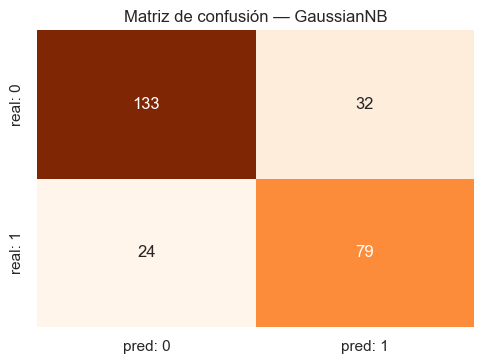

In [19]:
res_g = evaluar("GaussianNB", y_test, y_pred_g, y_proba_g)
plot_matriz(y_test, y_pred_g, "GaussianNB")


### Curva ROC — GaussianNB

Se gráfica la curva ROC del modelo sobre el conjunto de prueba.

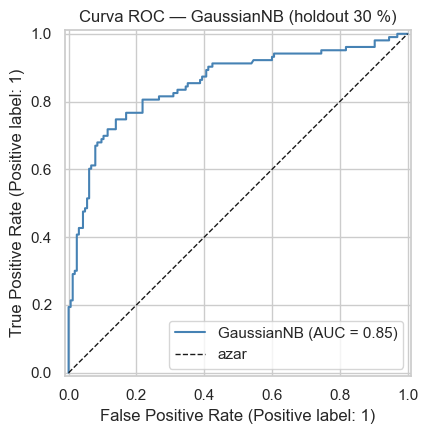

In [20]:
fig, ax = plt.subplots(figsize=(6, 4.5))
disp_g = RocCurveDisplay.from_predictions(y_test, y_proba_g, ax=ax, name="GaussianNB")
disp_g.line_.set_color("steelblue")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="azar")
ax.set_title("Curva ROC — GaussianNB (holdout 30 %)")
ax.legend()
plt.tight_layout()
plt.show()

### Validación cruzada — GaussianNB

5 folds estratificados sobre todo el dataset para estimar la varianza del resultado.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_gauss = cross_val_score(modelo_gauss, X, y, cv=cv, scoring="accuracy")
cv_gauss_f1 = cross_val_score(modelo_gauss, X, y, cv=cv, scoring="f1")

print("Validación cruzada estratificada (5 folds) sobre todo el dataset:")
print(f"  Accuracy: {cv_gauss.mean():.3f} ± {cv_gauss.std():.3f}  ->  {np.round(cv_gauss, 3)}")
print(f"  F1:       {cv_gauss_f1.mean():.3f} ± {cv_gauss_f1.std():.3f}  ->  {np.round(cv_gauss_f1, 3)}")


Validación cruzada estratificada (5 folds) sobre todo el dataset:
  Accuracy: 0.796 ± 0.008  ->  [0.793 0.792 0.798 0.787 0.809]
  F1:       0.738 ± 0.016  ->  [0.745 0.726 0.723 0.729 0.767]


## 12. Variante CategoricalNB (datos discretizados)

Comparamos contra la variante categórica para observar **cómo influyen los atípicos y la discretización** según la variante utilizada.


Valores >= 0 para CategoricalNB: True


--- CategoricalNB ---


                   precision    recall  f1-score   support

no sobrevivió (0)       0.82      0.80      0.81       165
   sobrevivió (1)       0.69      0.73      0.71       103

         accuracy                           0.77       268
        macro avg       0.76      0.76      0.76       268
     weighted avg       0.77      0.77      0.77       268



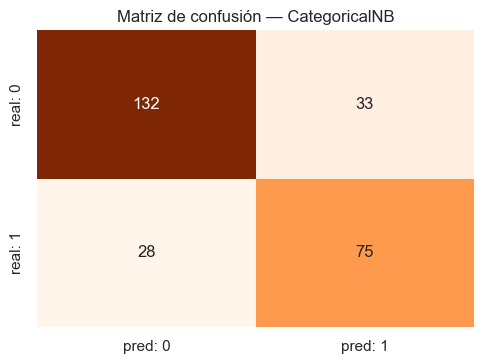

In [22]:
modelo_cat = Pipeline([
    ("prep", prep_cat),
    ("nb", CategoricalNB(alpha=1.0)),   # suavizado de Laplace (alpha=1) para evitar P=0
])

modelo_cat.fit(X_train, y_train)

X_test_cat = prep_cat.transform(X_test)
print("Valores >= 0 para CategoricalNB:", bool((X_test_cat >= 0).all()))

y_pred_c = modelo_cat.predict(X_test)
y_proba_c = modelo_cat.predict_proba(X_test)[:, 1]
res_c = evaluar("CategoricalNB", y_test, y_pred_c, y_proba_c)
plot_matriz(y_test, y_pred_c, "CategoricalNB")


### Validación cruzada y tabla comparativa — CategoricalNB

Mismos 5 folds para la variante discreta y tabla comparativa de ambas variantes.

In [23]:
cv_cat = cross_val_score(modelo_cat, X, y, cv=cv, scoring="accuracy")
cv_cat_f1 = cross_val_score(modelo_cat, X, y, cv=cv, scoring="f1")
print("Validación cruzada CategoricalNB (5 folds):")
print(f"  Accuracy: {cv_cat.mean():.3f} ± {cv_cat.std():.3f}  ->  {np.round(cv_cat, 3)}")
print(f"  F1:       {cv_cat_f1.mean():.3f} ± {cv_cat_f1.std():.3f}  ->  {np.round(cv_cat_f1, 3)}")

comparacion = pd.DataFrame([res_g, res_c]).set_index("Modelo").round(3)
comparacion["CV Accuracy (5 folds)"] = [round(cv_gauss.mean(), 3), round(cv_cat.mean(), 3)]
comparacion["CV F1 (5 folds)"] = [round(cv_gauss_f1.mean(), 3), round(cv_cat_f1.mean(), 3)]
comparacion


Validación cruzada CategoricalNB (5 folds):
  Accuracy: 0.796 ± 0.021  ->  [0.793 0.815 0.798 0.758 0.815]
  F1:       0.738 ± 0.028  ->  [0.745 0.756 0.719 0.695 0.776]


,Accuracy,Precision,Recall,F1,ROC-AUC,CV Accuracy (5 folds),CV F1 (5 folds)
Modelo,,,,,,,
GaussianNB,0.791,0.712,0.767,0.738,0.853,0.796,0.738
CategoricalNB,0.772,0.694,0.728,0.711,0.840,0.796,0.738


### Curva ROC comparativa

Se superponen las curvas de GaussianNB y CategoricalNB en un mismo gráfico.

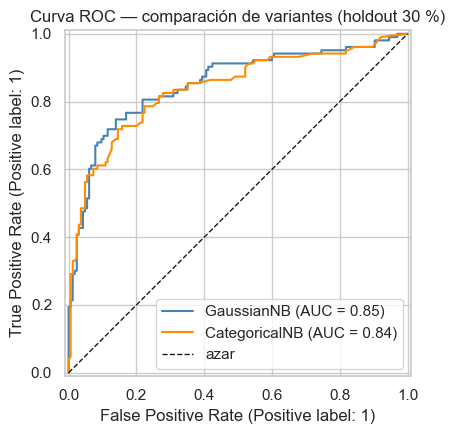

In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))
disp_g = RocCurveDisplay.from_predictions(y_test, y_proba_g, ax=ax, name="GaussianNB")
disp_g.line_.set_color("steelblue")
disp_c = RocCurveDisplay.from_predictions(y_test, y_proba_c, ax=ax, name="CategoricalNB")
disp_c.line_.set_color("darkorange")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="azar")
ax.set_title("Curva ROC — comparación de variantes (holdout 30 %)")
ax.legend()
plt.tight_layout()
plt.show()

## 13. Conclusión

**Por qué Naive Bayes es buena opción.** El Titanic es un problema clásico de clasificación binaria con pocas variables y muestras limitadas (891 registros), justamente el escenario donde Naive Bayes rinde mejor: entrena en milisegundos, tiene pocos hiperparámetros (`alpha`, `var_smoothing`) y entrega **probabilidades calibradas** de supervivencia, no solo una etiqueta, lo cual es útil para priorizar rescates/análisis. Además, gran parte de los atributos son categóricos (`Sex`, `Embarked`, `Title`, `Pclass`), formato nativo de la variante **CategoricalNB**, y las verosimilitudes $P(x_i \mid y)$ que estima son directamente interpretables (p. ej. `Sex=female` aporta fuerte evidencia a la clase "sobrevivió").

**Límites.** El supuesto central de **independencia condicional** es violado en este dataset: `Pclass`, `Fare_log` y `HasCabin` están correlacionados, así como `Title` y `Sex`; Naive Bayes multiplica evidencias redundantes y suele dar probabilidades demasiado seguras. La variante **GaussianNB** asume normalidad por atributo, incumplida antes de transformar (`Fare` con asimetría 4.79) y solo aproximada luego del `log1p`. La **discretización** necesaria para CategoricalNB pierde información dentro de cada bin. Por último, el desbalance 61.6/38.4 sesga hacia predecir "no sobrevivió", por lo que se reportan Recall, F1 y AUC además de accuracy.

**Ventajas.** Velocidad y escalabilidad; robustez ante atípicos (no usa distancias); funciona bien con one-hot de alta dimensionalidad; base probabilística interpretable; resistente al sobreentrenamiento con pocos datos (gracias al suavizado de Laplace).

**Mejoras posibles.**
- **Variables**: `Deck` (letra de cabina) para los 204 pasajeros con cabina conocida, `IsAlone`, `Fare por persona`, puerto + clase combinados; usar los 891 registros del split público de Kaggle más el de test (178) si estuvieran disponibles.
- **Datos**: imputación más fina de `Age` (KNNImputer), balanceo de clases, más registros históricos.
- **Modelado**: comparar con **Regresión Logística** (baseline probabilístico sin supuesto de independencia), **Random Forest / XGBoost** (capturan interacciones no lineales) y **SVM**; ajustar `alpha` y `var_smoothing` por validación; usar **Bayes Ingenuo Bayesano** para relajar la independencia; evaluar con AUC-PR y curvas de calibración.

**Conclusión corta:** Naive Bayes es un modelo de partida excelente —rápido, interpretable y probabilístico— para este problema: en este notebook, GaussianNB obtuvo **accuracy 0.791 y AUC 0.853** en el holdout (validación cruzada 5-fold: accuracy 0.796 ± 0.008) y CategoricalNB **0.772 / 0.840**, ambos muy por encima del 61.6 % que daría adivinar siempre "no sobrevivió". Sus límites (independencia condicional y normalidad) indican que, con datos e ingeniería de features suficientes, un modelo que modela dependencias debería superarlo.
